# 01 — RECON-SL Dataset Inspection and Audit

**Project:** Sri Lankan Household Electricity Consumption Prediction Using Ensemble Learning
**Dataset:** RECON-SL (LIRNEasia & LECO) — Zenodo record 15023048, CC-BY-4.0, DOI 10.21227/n1dk-q860

This notebook inspects the *actual* downloaded files before any modelling. Every statement about the
data is backed by a cell output below. No model is trained here.

**Sections**
1. Setup and directory structure
2. Monthly consumption file — schema, parsing, missing values, coverage
3. Zeros, extreme values and catch-up billing
4. Measurement-unit verification
5. Survey waves — timing relative to the consumption period
6. Survey tables — structure, attrition and household linkage
7. Stability of household characteristics between waves
8. Smart-meter files (summary of `scripts/audit_smart_meter.py`)
9. Data-quality issue register
10. Recommended prediction strategy

In [1]:
import sys, json, glob, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_loader import (RAW_DIR, MONTHLY_PATH, SURVEY_DIR, CONSUMPTION_UNIT,
                             load_monthly_consumption, load_survey_dates, load_survey_table)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
NAVY, TEAL, GRAY = "#1B2A4A", "#0F9D8F", "#9AA5B1"
print("Project root:", ROOT.name)

Project root: MLL


## 1. Directory structure of the downloaded dataset

In [2]:
for p in sorted(RAW_DIR.rglob("*")):
    if p.is_file() and "_download" not in p.parts:
        print(f"{p.stat().st_size/1e6:9.2f} MB  {p.relative_to(RAW_DIR)}")

     0.00 MB  consumption_data\documentation\data_dictionary.csv
     2.18 MB  consumption_data\non_smart_meter\monthly_consumption.csv
   948.90 MB  consumption_data\smart_meter\15min_interval\smart_15min_1.csv
  1696.95 MB  consumption_data\smart_meter\15min_interval\smart_15min_2.csv
  2015.23 MB  consumption_data\smart_meter\15min_interval\smart_15min_3.csv
   252.07 MB  consumption_data\smart_meter\6hour_interval\smart_6hour_1.csv
   299.66 MB  consumption_data\smart_meter\6hour_interval\smart_6hour_2.csv
   238.68 MB  consumption_data\smart_meter\6hour_interval\smart_6hour_3.csv
   156.05 MB  consumption_data\smart_meter\6hour_interval\smart_6hour_4.csv
    64.57 MB  consumption_data\smart_meter\6hour_interval\smart_6hour_5.csv
     0.01 MB  readme.md
     0.03 MB  survey_data\documentation\data_dictionaries\w1_data_dictionary.xlsx
     0.05 MB  survey_data\documentation\data_dictionaries\w2_data_dictionary.xlsx
     0.52 MB  survey_data\documentation\data_dictionaries\w3_data_di

**Observation.** The official GitHub repository contains only documentation and notebooks — the data itself is
distributed as one `data.zip` (≈1.18 GB) on Zenodo / IEEE DataPort / Kaggle. Inside it, the monthly file is small
(≈2 MB) while the smart-meter files are ≈5.7 GB uncompressed.

## 2. Monthly consumption file
### 2.1 Raw schema (read as text first, so nothing is silently converted)

In [3]:
raw = pd.read_csv(MONTHLY_PATH, dtype=str, keep_default_na=False)
print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
display(raw.head())
print("Empty consumption strings:", (raw.consumption == "").sum())
print("Values containing a comma:", raw.consumption.str.contains(",").sum())
print("Examples:", raw.loc[raw.consumption.str.contains(","), "consumption"].head(8).tolist())
naive = pd.to_numeric(raw.consumption, errors="coerce")
print("Naive pd.to_numeric -> NaN count:", naive.isna().sum(), "(590 genuine blanks + comma-formatted values)")

Shape: (101575, 3)
Columns: ['household_ID', 'month', 'consumption']


,household_ID,month,consumption
0,ID0001,2022-10-31,116
1,ID0001,2022-11-30,120
2,ID0001,2022-12-31,129
3,ID0001,2023-01-31,102
4,ID0001,2023-02-28,115


Empty consumption strings: 590
Values containing a comma: 57
Examples: ['1,644', '1,701', '1,346', '1,399', '1,297', '1,197', '1,159', '1,332']
Naive pd.to_numeric -> NaN count: 647 (590 genuine blanks + comma-formatted values)


**Issue found:** values ≥ 1,000 are written with a thousands separator (e.g. `"1,159"`). A naive numeric conversion turns
them into NaN and would *silently remove the highest-consuming households*. `src/data_loader.parse_consumption` strips
the comma and raises an error if any other non-numeric format appears.

In [4]:
df = load_monthly_consumption()
print(df.dtypes, "\n")
print("Rows:", len(df), "| households:", df.household_ID.nunique(), "| months:", df.month.nunique())
print("Period:", df.month.min().strftime("%Y-%m"), "to", df.month.max().strftime("%Y-%m"))
print("Missing consumption:", df.consumption.isna().sum(), f"({df.consumption.isna().mean():.2%})")
print("Duplicate (household, month) keys:", df.duplicated(["household_ID", "month"]).sum())
print("Negative values:", (df.consumption < 0).sum(), "| zeros:", (df.consumption == 0).sum())
print("All non-missing values are whole numbers:", bool((df.consumption.dropna() % 1 == 0).all()))
print("Rows per household:", df.groupby("household_ID").size().unique())
df.consumption.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99, .999]).round(1).to_frame().T

household_ID               str
month           datetime64[us]
consumption            float64
dtype: object 



Rows: 101575 | households: 4063 | months: 25
Period: 2022-10 to 2024-10
Missing consumption: 590 (0.58%)
Duplicate (household, month) keys: 0
Negative values: 0 | zeros: 2332
All non-missing values are whole numbers: True
Rows per household: [25]


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,99.9%,max
consumption,100985.0,122.1,122.2,0.0,0.0,10.0,60.0,96.0,148.0,306.0,577.0,1390.1,3025.0


**Observation.** The panel is *balanced*: every one of the 4,063 households has exactly one row for each of the 25 months
(Oct 2022 – Oct 2024). The README says "20 months"; the actual file contains **25**. Missing readings appear as blank
values (590 rows), not as missing rows.

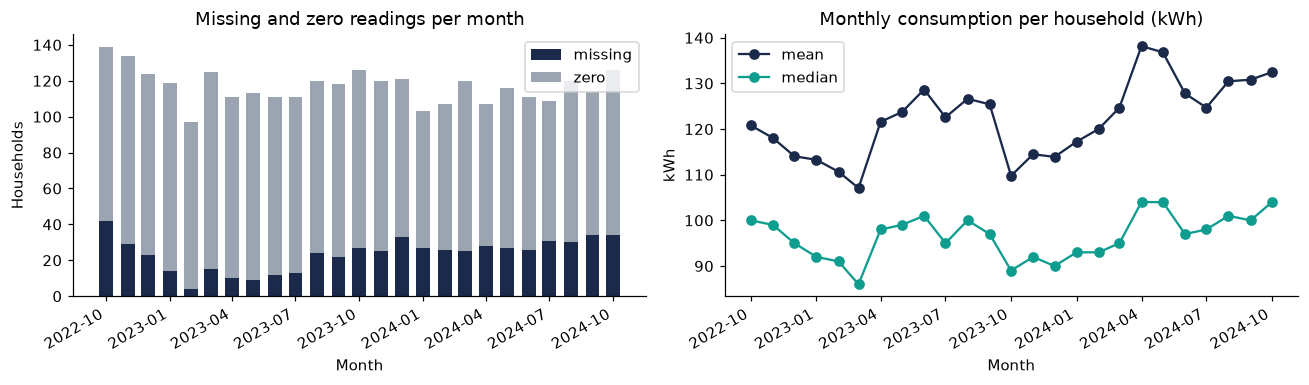

month,2022-10-01,2022-11-01,2022-12-01,2023-01-01,2023-02-01,2023-03-01,2023-04-01,2023-05-01,2023-06-01,2023-07-01,2023-08-01,2023-09-01,2023-10-01,2023-11-01,2023-12-01,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01
missing,42.0,29.0,23.0,14.0,4.0,15.0,10.0,9.0,12.0,13.0,24.0,22.0,27.0,25.0,33.0,27.0,26.0,25.0,28.0,27.0,26.0,31.0,30.0,34.0,34.0
zeros,97.0,105.0,101.0,105.0,93.0,110.0,101.0,104.0,99.0,98.0,96.0,96.0,99.0,95.0,88.0,76.0,81.0,95.0,79.0,89.0,85.0,78.0,90.0,80.0,92.0
mean,120.8,118.0,114.0,113.3,110.6,107.1,121.6,123.7,128.7,122.6,126.6,125.4,109.8,114.5,113.9,117.2,120.0,124.7,138.2,136.8,127.8,124.7,130.5,130.8,132.5
median,100.0,99.0,95.0,92.0,91.0,86.0,98.0,99.0,101.0,95.0,100.0,97.0,89.0,92.0,90.0,93.0,93.0,95.0,104.0,104.0,97.0,98.0,101.0,100.0,104.0


In [5]:
per_month = df.groupby("month").agg(missing=("consumption", lambda s: s.isna().sum()),
                                    zeros=("consumption", lambda s: (s == 0).sum()),
                                    mean=("consumption", "mean"), median=("consumption", "median"))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(per_month.index, per_month.missing, width=20, color=NAVY, label="missing")
ax[0].bar(per_month.index, per_month.zeros, width=20, bottom=per_month.missing, color=GRAY, label="zero")
ax[0].set(title="Missing and zero readings per month", ylabel="Households", xlabel="Month"); ax[0].legend()
ax[1].plot(per_month.index, per_month["mean"], color=NAVY, marker="o", label="mean")
ax[1].plot(per_month.index, per_month["median"], color=TEAL, marker="o", label="median")
ax[1].set(title=f"Monthly consumption per household ({CONSUMPTION_UNIT})", ylabel=CONSUMPTION_UNIT, xlabel="Month"); ax[1].legend()
fig.autofmt_xdate(); plt.tight_layout(); plt.show()
per_month.round(1).T

_Chart notes:_ left — data completeness per month; right — central tendency over time. The mean is well above the median, showing right skew (a minority of high consumers).

## 3. Zeros, extreme values and catch-up billing

In [6]:
wide = df.pivot(index="household_ID", columns="month", values="consumption")
zeros = (wide == 0).sum(axis=1); miss = wide.isna().sum(axis=1)
print("Households with ≥1 zero month:", (zeros > 0).sum(), "| zero in all 25 months:", (zeros == 25).sum())
print("Households with ≥1 missing month:", (miss > 0).sum())
hh_mean = wide.mean(axis=1)
print("Households with mean > 1,000 kWh:", (hh_mean > 1000).sum(), "| with any month > 1,000:", (wide > 1000).any(axis=1).sum())
ratio = wide.div(wide.median(axis=1).replace(0, np.nan), axis=0)
print("Household-months > 10× that household's median:", int((ratio > 10).sum().sum()))

Households with ≥1 zero month: 437 | zero in all 25 months: 13
Households with ≥1 missing month: 165
Households with mean > 1,000 kWh: 9 | with any month > 1,000: 36
Household-months > 10× that household's median: 164


In [7]:
examples = ["ID2759", "ID1247", "ID0661", "ID3178"]
show = wide.loc[examples].copy(); show.columns = [c.strftime("%y-%m") for c in show.columns]
show.astype("Int64")

,22-10,22-11,22-12,23-01,23-02,23-03,23-04,23-05,23-06,23-07,23-08,23-09,23-10,23-11,23-12,24-01,24-02,24-03,24-04,24-05,24-06,24-07,24-08,24-09,24-10
household_ID,,,,,,,,,,,,,,,,,,,,,,,,,
ID2759,<NA>,<NA>,<NA>,3025,414,357,397,344,425,369,<NA>,<NA>,<NA>,<NA>,<NA>,642,317,389,436,405,432,464,475,427,442
ID1247,90,90,90,0,118,31,31,31,31,31,31,31,30,30,2257,258,223,250,244,239,623,587,115,229,190
ID0661,120,205,282,315,362,292,<NA>,0,235,354,242,329,355,462,343,407,342,425,414,388,414,558,561,2587,329
ID3178,1660,1825,2175,1907,1963,1935,1935,1845,2215,2400,2520,2210,2170,2500,2140,2590,2370,2240,1920,1940,2070,2180,2300,2480,2370


**Two different kinds of extreme values**

* **Catch-up / accumulated readings** — e.g. ID2759 (missing months then 3,025), ID1247 (a flat run of 31 — an
  estimated bill — then 2,257). After missed or estimated meter readings, the next bill contains several months of
  consumption at once. These are *billing artefacts*, not real one-month usage.
* **Genuinely high consumers** — e.g. ID3178 is consistently ≈2,000 kWh every month. These must be kept.

Therefore extreme values must be handled by *pattern* (spike following missing/zero/flat months), not by a blanket cap.
The exact rule will be defined and justified in notebook 02.

**Zeros** can mean a vacant house, a disconnected meter, solar net-metering offsetting imports, or an unread meter.
13 households are zero in all 25 months. The next cell checks whether zeros are explained by solar ownership (Wave 1).

In [8]:
gen = load_survey_table(1, "electricity_generation_water_heating_cooking").set_index("household_ID")
solar = gen.generate_electicity_using_solar_energy.reindex(wide.index).eq("Yes")
zero_share = (wide == 0).mean(axis=1)
grp = pd.cut(zero_share, [-0.01, 0, 0.2, 0.99, 1], labels=["no zeros", "1–20% zero", "20–99% zero", "always zero"])
pd.DataFrame({"households": grp.value_counts().sort_index(), "solar share": solar.groupby(grp, observed=True).mean().round(3)})

,households,solar share
no zeros,3626,0.102
1–20% zero,310,0.090
20–99% zero,114,0.053
always zero,13,0.077


Solar households are *not* over-represented among zero readings (≈10% overall), so zeros are **not** mainly caused by
solar net-metering. Billed `consumption` appears to be grid import. Zeros are more likely vacancy, disconnection or
unread meters — to be handled in notebook 02.

In [9]:
pairs = pd.DataFrame({"current": wide.iloc[:, 1:].stack(), "previous": wide.shift(1, axis=1).iloc[:, 1:].stack()})
print("Correlation between a month and the previous month:", round(pairs.corr().iloc[0, 1], 3))

Correlation between a month and the previous month: 0.926


**Important for modelling:** month-to-month correlation is very high. A naive *“same as last month”* forecast is therefore
a strong baseline; ensemble models must be compared against it to show real added value.

## 4. Measurement-unit verification

In [10]:
dd = pd.read_csv(RAW_DIR / "consumption_data/documentation/data_dictionary.csv", encoding="utf-8-sig")
dd[dd.feature.isin(["consumption", "importkwh(kwh)", "TOTAL_IMPORT (kWh)"])]

,data_type,interval,feature,description
2,NaN,NaN,consumption,Total consumed units in kilowatts (KW)
6,NaN,NaN,importkwh(kwh),NaN
30,NaN,NaN,TOTAL_IMPORT (kWh),Total Cumulative consumed energy units


The official dictionary describes `consumption` as *“Total consumed units in kilowatts (KW)”*. This wording is
physically inconsistent: kW is a unit of **power**, whereas a monthly total is **energy**. The unit was therefore checked
against every available documentation source before deciding:

| Source | What it says about the monthly `consumption` unit |
|---|---|
| Data dictionary (GitHub & Zenodo zip), dataset README | “Total consumed units in kilowatts (KW)” — inconsistent wording |
| Zenodo record description | No unit stated |
| Survey questionnaire (97 pages) | Uses the Sri Lankan billing term “units” without defining it |
| **Dataset descriptor paper** — Algama et al., *Residential Electricity Consumption Dataset for Sri Lanka (RECON-SL)*, arXiv:2609.28783 (2026), section “Records and Storage” | **“Monthly consumption data provides direct usage in kilowatt-hours”** |
| Same paper, “Dataset Composition” | Records “capture cumulative electricity usage at the end of each billing cycle” |
| LIRNEasia's own analysis notebooks (`eda_with_nsm.ipynb`, `policy_brief.ipynb`) that load `monthly_consumption.csv` | Axis labels “Average Consumption (KWh)”, “Consumption Bin (kWh)” |

The dataset authors' descriptor explicitly states **kilowatt-hours**. As an independent empirical check,
`scripts/audit_smart_meter.py` computes each smart-metered household's calendar-month import from the cumulative 6-hour
**kWh** register and compares it with the billed monthly `consumption` for the same household.

{
  "matched_household_months": 28978,
  "matched_households": 1438,
  "pearson_corr_billed_vs_smart_kwh": 0.28851365347701274,
  "median_ratio_billed_over_smart_kwh": 0.9939694000100251,
  "ratio_iqr": [
    0.9172063544894492,
    1.0776069430005972
  ],
  "share_within_10pct": 0.5788548114800225,
  "corr_with_smart_kwh_previous_month": 0.30978574876656995,
  "corr_with_smart_kwh_next_month": 0.28149356207170284
}


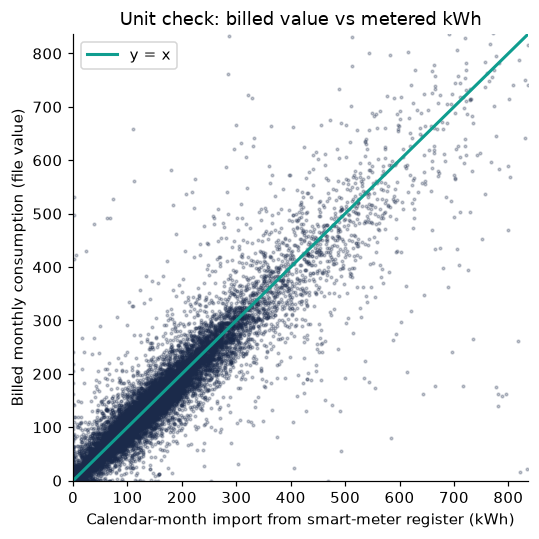

In [11]:
audit_path = ROOT / "reports/smart_meter_audit.json"
if audit_path.exists():
    audit = json.loads(audit_path.read_text())
    print(json.dumps(audit["unit_check"], indent=2))
    uc = pd.read_csv(ROOT / "reports/unit_check_6hour_vs_monthly.csv")
    lim = uc[["smart_kwh", "consumption"]].quantile(0.995).max()
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(uc.smart_kwh, uc.consumption, s=3, alpha=0.25, color=NAVY)
    ax.plot([0, lim], [0, lim], color=TEAL, lw=2, label="y = x")
    ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="Calendar-month import from smart-meter register (kWh)",
           ylabel="Billed monthly consumption (file value)", title="Unit check: billed value vs metered kWh")
    ax.legend(); plt.tight_layout(); plt.show()
else:
    print("Run `python scripts/audit_smart_meter.py` first.")

_Chart notes:_ each point is one household-month. Points lying along y = x mean the billed value equals metered kWh. Spread around the line is expected because billing cycles are not calendar months.

In [12]:
# Robust re-check from the saved comparison table, plus billing-month alignment
uc = pd.read_csv(ROOT / "reports/unit_check_6hour_vs_monthly.csv", parse_dates=["month"])
uc = uc[uc.smart_kwh <= 5000].sort_values(["household_ID", "month"])
uc["smart_kwh_prev_month"] = uc.groupby("household_ID").smart_kwh.shift(1)
p = uc.dropna(subset=["smart_kwh_prev_month"])
r = (uc.consumption / uc.smart_kwh).where(uc.smart_kwh > 0)
print(f"Household-months compared: {len(uc):,} | households: {uc.household_ID.nunique():,}")
print(f"Mean billed = {uc.consumption.mean():.1f} | mean metered kWh = {uc.smart_kwh.mean():.1f}")
print(f"Median billed/metered ratio = {r.median():.3f} (IQR {r.quantile(.25):.3f}–{r.quantile(.75):.3f})")
print(f"Spearman billed vs SAME calendar month   = {p.consumption.corr(p.smart_kwh, method='spearman'):.3f}, "
      f"median |diff| = {(p.consumption - p.smart_kwh).abs().median():.1f} kWh")
print(f"Spearman billed vs PREVIOUS calendar month = {p.consumption.corr(p.smart_kwh_prev_month, method='spearman'):.3f}, "
      f"median |diff| = {(p.consumption - p.smart_kwh_prev_month).abs().median():.1f} kWh")

Household-months compared: 28,959 | households: 1,438
Mean billed = 128.7 | mean metered kWh = 130.1
Median billed/metered ratio = 0.993 (IQR 0.915–1.077)


Spearman billed vs SAME calendar month   = 0.954, median |diff| = 7.7 kWh
Spearman billed vs PREVIOUS calendar month = 0.981, median |diff| = 2.0 kWh


**Conclusion — unit:** `consumption` is **energy in kWh**. This is (1) stated explicitly by the dataset authors'
descriptor paper and (2) confirmed empirically: billed values agree with metered kWh (ratio ≈ 1, means almost identical,
rank correlation ≈ 0.95). The dictionary's “kilowatts (KW)” is a documentation wording discrepancy (kW is power, not
energy); the project uses **kWh** consistently and records this discrepancy in the README.

**Conclusion — billing month:** the value labelled month *m* matches the meter's energy for calendar month *m − 1* much
more closely. `month` is therefore the **billing month**; most of the energy was consumed in the previous month. This
matters when interpreting seasonal patterns and when comparing with survey dates. It does not create leakage, because
lag features are built from earlier billing months only.

## 5. Survey waves — when were they collected?

Households in survey_dates: 4063
wave1: n=4063  from 2023-12-09 to 2024-10-24
wave2: n=3515  from 2024-09-08 to 2024-12-17
wave3: n=3396  from 2024-10-18 to 2025-01-12
Households in all three waves: 3395


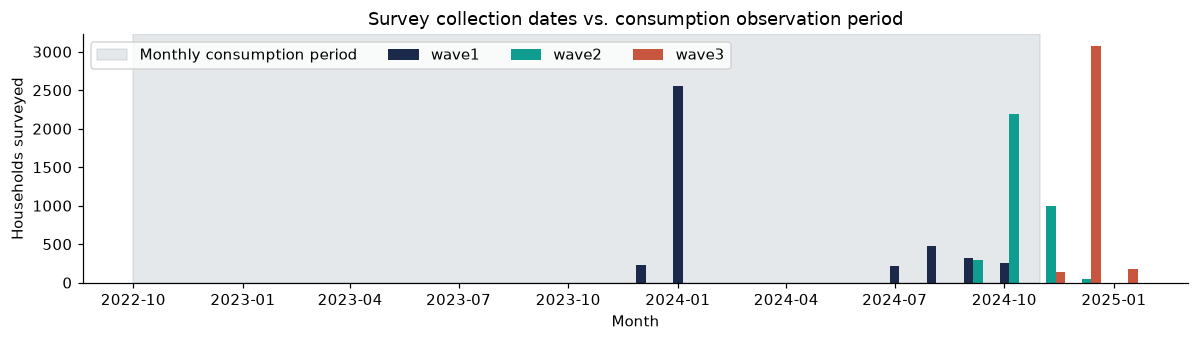

In [13]:
sd = load_survey_dates()
print("Households in survey_dates:", len(sd))
for w in ["wave1", "wave2", "wave3"]:
    print(f"{w}: n={sd[w].notna().sum():4d}  from {sd[w].min().date()} to {sd[w].max().date()}")
print("Households in all three waves:", sd[["wave1", "wave2", "wave3"]].notna().all(axis=1).sum())
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.axvspan(df.month.min(), df.month.max() + pd.offsets.MonthEnd(0), color=GRAY, alpha=0.25, label="Monthly consumption period")
for i, (w, c) in enumerate(zip(["wave1", "wave2", "wave3"], [NAVY, TEAL, "#C8553D"])):
    counts = sd[w].dropna().dt.to_period("M").value_counts().sort_index()
    ax.bar(counts.index.to_timestamp() + pd.Timedelta(days=8 * i), counts.values, width=8, color=c, label=w)
ax.set(title="Survey collection dates vs. consumption observation period", ylabel="Households surveyed", xlabel="Month")
ax.legend(ncol=4, loc="upper left"); plt.tight_layout(); plt.show()

**Decision:** the main experiment uses **Wave 1 features only**; Waves 2 and 3 are excluded as predictors.

**Key finding (leakage):** the consumption data ends in **October 2024**.
* Wave 1 was collected Dec 2023 – Oct 2024 (most in Jan 2024) — *during* the consumption period.
* Wave 2 (Sep–Dec 2024) and Wave 3 (Oct 2024–Jan 2025) were collected at or **after** the end of the consumption data.

Using Wave 2/3 answers to predict 2022–2024 consumption would use information from the future. They are therefore
**excluded as predictors**. Wave 1 is the only candidate, under the assumption that slowly-changing structural
characteristics (house type, floor area, household size, appliance stock) describe the household throughout the period.
Section 7 tests how reasonable that assumption is.

## 6. Survey tables — structure, attrition and linkage

In [14]:
cons_ids = set(df.household_ID)
rows = []
for f in sorted(glob.glob(str(SURVEY_DIR / "wave_*" / "*.csv"))):
    d = pd.read_csv(f, low_memory=False)
    idc = [c for c in d.columns if c.lower() == "household_id"][0]
    ids = set(d[idc].dropna())
    rows.append(dict(table=Path(f).name, rows=len(d), cols=d.shape[1], households=len(ids),
                     rows_per_household=round(len(d) / max(len(ids), 1), 1),
                     missing_household_id=int(d[idc].isna().sum()), ids_not_in_consumption=len(ids - cons_ids),
                     pct_cells_missing=round(100 * d.isna().mean().mean(), 1), duplicate_rows=int(d.duplicated().sum())))
survey_audit = pd.DataFrame(rows); survey_audit

,table,rows,cols,households,rows_per_household,missing_household_id,ids_not_in_consumption,pct_cells_missing,duplicate_rows
0,w1_ac_roster.csv,1171,10,562,2.1,0,0,7.8,0
1,w1_appliances.csv,53599,4,4055,13.2,0,0,10.2,0
2,w1_demographics.csv,16270,16,4063,4.0,0,0,17.4,0
3,w1_electricity_generation_water_heating_cookin...,4063,36,4063,1.0,0,0,35.6,0
4,w1_fan_roster.csv,13525,6,3817,3.5,0,0,0.0,0
5,w1_household_information_and_history.csv,4063,26,4063,1.0,0,0,26.2,0
6,w1_light_roster.csv,48489,7,4054,12.0,0,0,2.7,0
7,w1_room_roster.csv,36408,16,4063,9.0,0,0,16.2,0
8,w2_ac_roster.csv,854,9,418,2.0,0,0,2.5,0
9,w2_appliance_usage.csv,41594,4,3392,12.3,20,1,10.2,0


**Linkage.** `household_ID` (format `ID0001`) is the common key between the monthly file, `survey_dates.csv` and every
survey table. All 4,063 monthly households appear in Wave 1; no survey ID is absent from the consumption file (one blank
ID in several Wave 2/3 tables).

**Table grain.** `household_information`, `electricity_generation…` are one row per household. Rosters (`appliances`,
`room`, `light`, `fan`, `ac`) and `demographics` are one row per item/person — they must be **aggregated to household
level** (e.g. count of ACs, refrigerators, fans) before joining, otherwise the join would duplicate consumption rows.

**Attrition.** 4,063 households (W1) → ~3,500 (W2) → ~3,397 (W3).

**Missing values** in survey tables are mostly *structural* (skip logic: e.g. solar questions are blank for households
without solar), not random — they will be encoded as “not applicable” rather than imputed blindly.

In [15]:
h1 = load_survey_table(1, "household_information_and_history")
for c in ["electricity_provider_csc_area", "type_of_house", "socio_economic_class", "type_of_electricity_meter", "built_year_of_the_house"]:
    print(f"\n{c} ({h1[c].nunique()} categories):", h1[c].value_counts().head(8).to_dict())
h1[["no_of_household_members", "floor_area", "total_monthly_expenditure_of_last_month", "no_of_electricity_meters"]].describe().round(1)


electricity_provider_csc_area (23 categories): {'MORATUWA NORTH': 533, 'MORATUWA SOUTH': 370, 'PANADURA': 357, 'GALLE': 216, 'KESELWATTA': 206, 'MAHARAGAMA': 202, 'PAYAGALA': 196, 'KALUTARA': 189}

type_of_house (10 categories): {'Single House - Single Floor': 2482, 'Single House - Double Floor': 1332, 'Single House - More than 2 floors': 113, 'Flat': 80, 'Condominium/ Luxury apartments': 13, 'Slum / Shanty': 11, 'Line room/row house': 11, 'Attached house / Annex': 10}

socio_economic_class (5 categories): {'SEC C': 1485, 'SEC B': 868, 'SEC A': 786, 'SEC D': 669, 'SEC E': 255}

type_of_electricity_meter (2 categories): {'Smart meter': 2186, 'Non smart meter': 1877}

built_year_of_the_house (7 categories): {'2000-2009': 918, '2010-2019': 758, 'Before 1980': 740, '1990-1999': 615, '1980-1989': 482, "Don't know": 325, 'In 2020 or After 2020': 225}


,no_of_household_members,floor_area,total_monthly_expenditure_of_last_month,no_of_electricity_meters
count,4063.0,4037.0,3928.0,4063.0
mean,4.0,1356.2,71327.3,1.1
std,1.7,950.2,44311.4,0.3
min,1.0,100.0,5000.0,1.0
25%,3.0,600.0,40000.0,1.0
50%,4.0,1000.0,60000.0,1.0
75%,5.0,2000.0,100000.0,1.0
max,13.0,9000.0,275000.0,7.0


In [16]:
app = load_survey_table(1, "appliances")
print("Distinct appliance types:", app.appliance_type.nunique())
app.appliance_type.value_counts().head(20).to_frame("rows in W1 roster")

Distinct appliance types: 77


,rows in W1 roster
appliance_type,
Mobile phone - Smart phones,7976
Refrigerator,3545
Electric Iron including electric steam iron,3535
TV,3402
Rice cooker,3223
Electric Blender,2989
Washing Machine,2395
Laptops,1802
Mobile phone - Basic phones,1733


## 7. Stability of household characteristics between Wave 1 and Wave 2

In [17]:
ca = load_survey_table(2, "changed_appliances")
changed = ca.groupby("household_ID").still_have_the_same_number_of_appliances_or_not.apply(lambda s: (s == "No").any())
print(f"Households with ≥1 appliance-count change W1→W2: {changed.mean():.1%}")
h2 = load_survey_table(2, "household_information")
for c in ["changes_to_the_structure_of_household_after_w1", "renovations_done_after_w1", "new_household_members"]:
    print(c, h2[c].value_counts(normalize=True).round(3).head(4).to_dict())

Households with ≥1 appliance-count change W1→W2: 37.2%
changes_to_the_structure_of_household_after_w1 {'No structural changes were done to the household': 0.983, 'Yes, new parts were added only': 0.013, 'Yes, some parts were dismantled only': 0.003, 'Yes, some new parts were added to the household and some parts were dismantled': 0.001}
renovations_done_after_w1 {'No': 0.947, 'Yes': 0.053}
new_household_members {0.0: 0.896, 1.0: 0.055, 2.0: 0.023, 3.0: 0.013}


**Interpretation.** Structural features (house type, floor area, construction) and household composition are largely
stable (≈98% no structural change; ≈90% no new members). Appliance stock changes more often (≈37% of households changed
the count of at least one appliance type). Wave-1 appliance counts are therefore an *approximation* for months far from
the Wave-1 date — a limitation to report, and a reason to test whether survey features genuinely improve accuracy.

## 8. Smart-meter files

In [18]:
if audit_path.exists():
    for kind in ["6hour", "15min"]:
        t = pd.DataFrame(audit[kind]).drop(columns=["columns", "missing_per_column"])
        print(f"\n=== {kind} ==="); display(t.T)
    print(json.dumps(audit["household_overlap"], indent=2))


=== 6hour ===


,0,1,2,3,4
file,smart_6hour_1.csv,smart_6hour_2.csv,smart_6hour_3.csv,smart_6hour_4.csv,smart_6hour_5.csv
rows,1115230,1319347,1047075,680674,279467
unique_households,2813,2922,2950,2929,2911
invalid_timestamps,4,7,0,0,0
date_min,2023-01-01 00:30:23,2023-06-02 00:30:22,2023-11-02 00:12:37,2024-04-02 00:30:42,2024-09-02 00:30:08
date_max,2023-06-01 23:55:07,2023-11-01 23:43:22,2024-04-01 19:24:35,2024-09-01 23:37:50,2024-12-31 18:36:27
import_non_numeric_or_missing,4,5,5,1,0
import_negative_values,0,0,0,0,0
duplicate_household_timestamp,0,1,0,0,0
rows_out_of_time_order_in_file,369611,444317,306847,150805,43519



=== 15min ===


,0,1,2
file,smart_15min_1.csv,smart_15min_2.csv,smart_15min_3.csv
rows,9435755,16425676,19751849
unique_households,2373,2878,2745
invalid_timestamps,0,0,0
date_min,2023-10-01 00:00:00,2024-03-02 00:00:00,2024-08-02 00:00:00
date_max,2024-03-01 23:45:00,2024-08-01 23:45:00,2024-12-23 12:00:00
import_non_numeric_or_missing,0,0,0
import_negative_values,0,0,0
duplicate_household_timestamp,0,0,0
rows_out_of_time_order_in_file,4660619,8173613,9666341


{
  "monthly_households": 4063,
  "6hour_households": 2950,
  "15min_households": 2938,
  "6hour_in_monthly": 1438,
  "15min_in_monthly": 1431,
  "6hour_and_15min": 2938,
  "smart_ids_not_in_monthly_examples": [
    "ID4064",
    "ID4065",
    "ID4066",
    "ID4067",
    "ID4068",
    "ID4069",
    "ID4070",
    "ID4071",
    "ID4072",
    "ID4073"
  ]
}


**Notes on smart-meter formats (verified from the raw files)**
* The smart-meter files contain ≈2,950 households, but only ≈1,440 of them are in the monthly/survey sample
  (IDs ≥ ID4064 exist only in smart-meter files and have no survey data).
* Reading frequency of the "6-hour" files degrades over time (median gap ≈6 h in 2023 → ≈24 h in late 2024).
* Energy columns are **cumulative registers in kWh** (`importkwh(kwh)`, `TOTAL_IMPORT (kWh)`); interval consumption is
  the difference between consecutive readings of the same household, after sorting by time.
* Rows are not stored in time order; the 15-minute `timestamp` column is rounded (precision ≈ hours) so `date` + `time`
  must be used instead.
* 6-hour reading times are irregular; gaps, register decreases (meter replacement/reset) and duplicates are counted above.
* Missing intervals must **not** be treated as zero consumption.
* Solar households export energy (`EXPORT=True`, `exportkwh`), which matters when interpreting low or zero billed values.

## 9. Data-quality issue register

| # | Issue | Evidence | Planned handling (notebooks 02/03) |
|---|---|---|---|
| 1 | `consumption` stored as text with thousands separators | 57 values like "1,159" | Strip comma, strict parse (done in `data_loader`) |
| 2 | Missing monthly readings | 590 blanks, 165 households | Keep as missing; never fill with 0; drop as *targets*, handle in lags |
| 3 | Zero readings | 2,332 rows; 13 households always zero | Investigate (vacancy / solar / estimated); likely exclude always-zero households |
| 4 | Catch-up spikes after missing/estimated months | e.g. ID2759, ID1247 | Rule-based flag; exclude flagged rows from training targets/lags; document |
| 5 | Unit wording "kilowatts (KW)" in dictionary | Dictionary text vs descriptor paper | **kWh** — stated in the RECON-SL descriptor paper and verified against smart-meter kWh registers (Section 4) |
| 5b | `month` is the billing month (energy mostly used in previous calendar month) | Section 4 | Document; interpret seasonality with a one-month shift |
| 5c | Smart-meter register jumps/resets | 19 impossible monthly jumps; thousands of register decreases | Exclude jumps when deriving kWh from registers |
| 6 | README says 20 months; file has 25 | Section 2 | Use actual 25 months |
| 7 | Wave 2/3 collected after consumption period | Section 5 | Exclude as predictors (future leakage) |
| 8 | Wave 1 collected during the period | Section 5 | Use only slowly-changing W1 features; test benefit explicitly |
| 9 | Survey rosters are item-level | Section 6 | Aggregate to household level before joining |
| 10 | Structural missingness in survey (skip logic) | Section 6 | Encode "not applicable" category |
| 11 | Smart-meter registers cumulative, unordered, gaps/resets | Section 8 | Optional experiment only; sort, diff, drop negative diffs |
| 12 | Strong month-to-month persistence | corr ≈ 0.93 | Include naive persistence baseline |

## 10. Recommended prediction strategy

* **Unit of analysis:** household-month. **Target:** `consumption` (kWh) for month *t*.
* **Main task (Scenario A — known households, future months):** predict month *t* using only information available
  before *t*: lags (*t−1, t−2, t−3*), shifted rolling means, the household's historical mean up to *t−1*, calendar month,
  and slowly-changing Wave-1 household characteristics.
* **Primary evaluation:** chronological hold-out — e.g. train on the earliest months, test on the final months
  (exact split decided in notebook 03); identical test period for all models.
* **Tuning / stacking:** expanding-window (time-ordered) validation inside the training period only.
* **Secondary experiment (Scenario B — unseen households):** GroupKFold by `household_ID`, to measure generalisation to
  new households. Reported separately from Scenario A.
* **Ablation:** consumption-history-only features vs. history + Wave-1 survey features (answers research question 2).
* **Smart-meter data:** used for unit verification and optional EDA, not as a core model input (it covers only part of
  the households and period).